# 01_Python — Exercícios de Python, NumPy e PyTorch

**Aluno: Tiago Galhardo Avelar**

Este notebook é uma cópia resolvida do modelo da disciplina. Todas as células foram executadas para registrar testes de correção, medições de eficiência e resultados numéricos.


## Coloque seu nome

In [1]:
print("Meu nome é: Tiago Galhardo Avelar")


Meu nome é: Tiago Galhardo Avelar


# Parte 1:

##Exercícios de Processamento de Dados

Nesta parte pode-se usar as bibliotecas nativas do python como a `collections`, `re` e `random`. Também pode-se usar o NumPy.

##Exercício 1.1
Crie um dicionário com os `k` itens mais frequentes de uma lista.

Por exemplo, dada a lista de itens `L=['a', 'a', 'd', 'b', 'd', 'c', 'e', 'a', 'b', 'e', 'e', 'a']` e `k=2`, o resultado deve ser um dicionário cuja chave é o item e o valor é a sua frequência: {'a': 4, 'e': 3}

In [2]:
from collections import Counter


def top_k(L, k):
    # Retorna os k itens mais frequentes, do mais para o menos frequente.
    if k < 0:
        raise ValueError("k deve ser não negativo")
    return dict(Counter(L).most_common(k))


Mostre que sua implementação está correta usando uma entrada com poucos itens:

In [3]:
L = ['f', 'a', 'a', 'd', 'b', 'd', 'c', 'e', 'a', 'b', 'e', 'e', 'a', 'd']
k = 3
resultado = top_k(L=L, k=k)
print(f"resultado: {resultado}")
assert resultado == {'a': 4, 'd': 3, 'e': 3}


resultado: {'a': 4, 'd': 3, 'e': 3}


Mostre que sua implementação é eficiente usando uma entrada com 10M de itens:

In [4]:
import random

random.seed(123)
L = random.choices('abcdefghijklmnopqrstuvwxyz', k=10_000_000)
k = 10_000
print("Itens gerados:", len(L))


Itens gerados: 10000000


In [5]:
%%timeit -n 1 -r 1
resultado = top_k(L=L, k=k)
assert len(resultado) == 26


329 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Exercício 1.2

Em processamento de linguagem natural, é comum convertemos as palavras de um texto para uma lista de identificadores dessas palavras. Dado o dicionário `V` abaixo onde as chaves são palavras e os valores são seus respectivos identificadores, converta o texto `D` para uma lista de identificadores.

Palavras que não existem no dicionário deverão ser convertidas para o identificador do token `unknown`.

O código deve ser insensível a maiúsculas (case-insensitive).

Se atente que pontuações (vírgulas, ponto final, etc) também são consideradas palavras.

In [6]:
import re


def tokens_to_ids(text, vocabulary):
    # Tokeniza palavras/pontuação e converte cada token para seu identificador.
    unknown_id = vocabulary['unknown']
    tokens = re.findall(r"\w+(?:'\w+)*|[^\w\s]", text.lower(), flags=re.UNICODE)
    return [vocabulary.get(token, unknown_id) for token in tokens]


Mostre que sua implementação esta correta com um exemplo pequeno:

---



In [7]:
V = {'eu': 1, 'de': 2, 'gosto': 3, 'comer': 4, '.': 5, 'unknown': -1}
D = 'Eu gosto de comer pizza.'

resultado = tokens_to_ids(D, V)
print(resultado)
assert resultado == [1, 3, 2, 4, -1, 5]


[1, 3, 2, 4, -1, 5]


Mostre que sua implementação é eficiente com um exemplo grande:

In [8]:
V = {'eu': 1, 'de': 2, 'gosto': 3, 'comer': 4, '.': 5, 'unknown': -1}
D = ' '.join(1_000_000 * ['Eu gosto de comer pizza.'])

In [9]:
%%timeit -n 1 -r 1
resultado = tokens_to_ids(D, V)
assert len(resultado) == 6_000_000


1.67 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Exercício 1.3

Em aprendizado profundo é comum termos que lidar com arquivos muito grandes.

Dado um arquivo de texto onde cada item é separado por `\n`, escreva um programa que amostre `k` itens desse arquivo aleatoriamente.

Nota 1: Assuma amostragem de uma distribuição uniforme, ou seja, todos os itens tem a mesma probablidade de amostragem.

Nota 2: Assuma que o arquivo não cabe em memória.

Nota 3: Utilize apenas bibliotecas nativas do python.

In [10]:
def sample(path: str, k: int):
    # Amostra k linhas uniformemente com reservoir sampling e memória O(k).
    if k < 0:
        raise ValueError("k deve ser não negativo")

    rng = random.Random(123)
    reservoir = []
    with open(path, encoding='utf-8') as source:
        for index, line in enumerate(source):
            item = line.rstrip('\n')
            if index < k:
                reservoir.append(item)
            else:
                replacement = rng.randint(0, index)
                if replacement < k:
                    reservoir[replacement] = item

    if len(reservoir) < k:
        raise ValueError("k é maior do que o número de itens do arquivo")
    return reservoir


Mostre que sua implementação está correta com um exemplo pequeno:

In [11]:
filename = 'small.txt'
total_size = 100
n_samples = 10

with open(filename, 'w', encoding='utf-8') as fout:
    fout.write('\n'.join(f'line {i}' for i in range(total_size)))

samples = sample(path=filename, k=n_samples)
print(samples)
print(len(samples) == n_samples)
assert len(samples) == n_samples
assert len(set(samples)) == n_samples


['line 37', 'line 95', 'line 89', 'line 16', 'line 74', 'line 42', 'line 40', 'line 30', 'line 45', 'line 84']
True


Mostre que sua implementação é eficiente com um exemplo grande:

In [12]:
filename = 'large.txt'
total_size = 1_000_000
n_samples = 10_000

with open(filename, 'w', encoding='utf-8') as fout:
    fout.write('\n'.join(f'line {i}' for i in range(total_size)))
print("Arquivo criado com", total_size, "linhas")


Arquivo criado com 1000000 linhas


In [13]:
%%timeit -n 1 -r 1
samples = sample(path=filename, k=n_samples)
assert len(samples) == n_samples


534 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


# Parte 2:

##Exercícios de Numpy

Nesta parte deve-se usar apenas a biblioteca NumPy. Aqui não se pode usar o PyTorch.

##Exercício 2.1

Quantos operações de ponto flutuante (flops) de soma e de multiplicação tem a multiplicação matricial $AB$, sendo que a matriz $A$ tem tamanho $m \times n$ e a matriz $B$ tem tamanho $n \times p$?

**Resposta:**

- número de somas: $m\,p\,(n-1)$;
- número de multiplicações: $m\,n\,p$.

Cada um dos $m\,p$ elementos da saída é um produto interno de comprimento $n$, contendo $n$ multiplicações e $n-1$ somas. Portanto, considerando ambas, o total é $m\,p\,(2n-1)$ operações de ponto flutuante.


## Exercício 2.2

Em programação matricial, não se faz o loop em cada elemento da matriz,
mas sim, utiliza-se operações matriciais.

Dada a matriz `A` abaixo, calcule a média dos valores de cada linha sem utilizar laços explícitos.

Utilize apenas a biblioteca numpy.

In [14]:
import numpy as np

In [15]:
A = np.arange(24).reshape(4, 6)
print(A)

[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]]


In [16]:
media_por_linha = A.mean(axis=1)
print(media_por_linha)
assert np.allclose(media_por_linha, [2.5, 8.5, 14.5, 20.5])


[ 2.5  8.5 14.5 20.5]


## Exercício 2.3

Seja a matriz $C$ que é a normalização da matriz $A$:
$$ C(i,j) = \frac{A(i,j) - A_{min}}{A_{max} - A_{min}} $$

Normalizar a matriz `A` do exercício acima de forma que seus valores fiquem entre 0 e 1.

In [17]:
A_float = A.astype(np.float64)
C = (A_float - A_float.min()) / (A_float.max() - A_float.min())
print(C)
assert np.isclose(C.min(), 0) and np.isclose(C.max(), 1)


[[0.         0.04347826 0.08695652 0.13043478 0.17391304 0.2173913 ]
 [0.26086957 0.30434783 0.34782609 0.39130435 0.43478261 0.47826087]
 [0.52173913 0.56521739 0.60869565 0.65217391 0.69565217 0.73913043]
 [0.7826087  0.82608696 0.86956522 0.91304348 0.95652174 1.        ]]


## Exercício 2.4

Modificar o exercício anterior de forma que os valores de cada *coluna* da matriz `A` sejam normalizados entre 0 e 1 independentemente dos valores das outras colunas.


In [18]:
min_coluna = A_float.min(axis=0, keepdims=True)
amplitude_coluna = A_float.max(axis=0, keepdims=True) - min_coluna
C_colunas = np.divide(
    A_float - min_coluna,
    amplitude_coluna,
    out=np.zeros_like(A_float),
    where=amplitude_coluna != 0,
)
print(C_colunas)
assert np.allclose(C_colunas.min(axis=0), 0)
assert np.allclose(C_colunas.max(axis=0), 1)


[[0.         0.         0.         0.         0.         0.        ]
 [0.33333333 0.33333333 0.33333333 0.33333333 0.33333333 0.33333333]
 [0.66666667 0.66666667 0.66666667 0.66666667 0.66666667 0.66666667]
 [1.         1.         1.         1.         1.         1.        ]]


## Exercício 2.5

Modificar o exercício anterior de forma que os valores de cada *linha* da matriz `A` sejam normalizados entre 0 e 1 independentemente dos valores das outras linhas.


In [19]:
min_linha = A_float.min(axis=1, keepdims=True)
amplitude_linha = A_float.max(axis=1, keepdims=True) - min_linha
C_linhas = np.divide(
    A_float - min_linha,
    amplitude_linha,
    out=np.zeros_like(A_float),
    where=amplitude_linha != 0,
)
print(C_linhas)
assert np.allclose(C_linhas.min(axis=1), 0)
assert np.allclose(C_linhas.max(axis=1), 1)


[[0.  0.2 0.4 0.6 0.8 1. ]
 [0.  0.2 0.4 0.6 0.8 1. ]
 [0.  0.2 0.4 0.6 0.8 1. ]
 [0.  0.2 0.4 0.6 0.8 1. ]]


## Exercício 2.6

A [função softmax](https://en.wikipedia.org/wiki/Softmax_function) é bastante usada em apredizado de máquina para converter uma lista de números para uma distribuição de probabilidade, isto é, os números ficarão normalizados entre zero e um e sua soma será igual à um.

Implemente a função softmax com suporte para batches, ou seja, o softmax deve ser aplicado a cada linha da matriz. Deve-se usar apenas a biblioteca numpy. Se atente que a exponenciação gera estouro de representação quando os números da entrada são muito grandes. Tente corrigir isto.

In [20]:
import numpy as np


def softmax(A):
    '''Aplica softmax de modo independente e numericamente estável em cada linha.'''
    values = np.asarray(A, dtype=np.float64)
    shifted = values - values.max(axis=1, keepdims=True)
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum(axis=1, keepdims=True)


Mostre que sua implementação está correta usando uma matriz pequena como entrada:

In [21]:
A = np.array([[0.5, -1, 1000],
              [-2,   0, 0.5]])
resultado_softmax = softmax(A)
print(resultado_softmax)


[[0.         0.         1.        ]
 [0.04861082 0.35918811 0.59220107]]


O código a seguir verifica se sua implementação do softmax está correta.
- A soma de cada linha de A deve ser 1;
- Os valores devem estar entre 0 e 1

In [22]:
teste_softmax = (
    np.allclose(softmax(A).sum(axis=1), 1)
    and softmax(A).min() >= 0
    and softmax(A).max() <= 1
    and np.isfinite(softmax(A)).all()
)
print("Softmax correto:", teste_softmax)
assert teste_softmax


Softmax correto: True


Mostre que sua implementação é eficiente usando uma matriz grande como entrada:

In [23]:
A = np.random.uniform(low=-10, high=10, size=(128, 100_000))

In [24]:
%%timeit -n 1 -r 1
softmax(A)


172 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [25]:
SM = softmax(A)
teste_grande = np.allclose(SM.sum(axis=1), 1) and SM.min() >= 0 and SM.max() <= 1
print("Softmax grande correto:", teste_grande, "forma:", SM.shape)
assert teste_grande


Softmax grande correto: True forma: (128, 100000)


## Exercício 2.7

A codificação one-hot é usada para codificar entradas categóricas. É uma codificação onde apenas um bit é 1 e os demais são zero, conforme a tabela a seguir.

| Decimal | Binary | One-hot
| ------- | ------ | -------
| 0 | 000    | 1 0 0 0 0 0 0 0
| 1 | 001    | 0 1 0 0 0 0 0 0
| 2 | 010    | 0 0 1 0 0 0 0 0
| 3 | 011    | 0 0 0 1 0 0 0 0
| 4 | 100    | 0 0 0 0 1 0 0 0
| 5 | 101    | 0 0 0 0 0 1 0 0
| 6 | 110    | 0 0 0 0 0 0 1 0
| 7 | 111    | 0 0 0 0 0 0 0 1

Implemente a função one_hot(y, n_classes) que codifique o vetor de inteiros y que possuem valores entre 0 e n_classes-1.


In [26]:
def one_hot(y, n_classes):
    labels = np.asarray(y, dtype=np.int64)
    if labels.ndim != 1:
        raise ValueError("y deve ser um vetor")
    if n_classes <= 0 or np.any(labels < 0) or np.any(labels >= n_classes):
        raise ValueError("rótulos fora do intervalo [0, n_classes)")
    encoded = np.zeros((labels.size, n_classes), dtype=np.uint8)
    encoded[np.arange(labels.size), labels] = 1
    return encoded


In [27]:
N_CLASSES = 9
N_SAMPLES = 10
y = (np.random.rand(N_SAMPLES) * N_CLASSES).astype(np.int64)
resultado_one_hot = one_hot(y, N_CLASSES)
print(y)
print(resultado_one_hot)
assert resultado_one_hot.shape == (N_SAMPLES, N_CLASSES)
assert np.all(resultado_one_hot.sum(axis=1) == 1)


[3 3 2 4 7 4 6 6 8 2]
[[0 0 0 1 0 0 0 0 0]
 [0 0 0 1 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 1 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 1 0 0]
 [0 0 0 0 0 0 0 0 1]
 [0 0 1 0 0 0 0 0 0]]


Mostre que sua implementação é eficiente usando uma matriz grande como entrada:

In [28]:
N_SAMPLES = 100_000
N_CLASSES = 1_000
y = (np.random.rand(N_SAMPLES) * N_CLASSES).astype(np.int64)


In [29]:
%%timeit -n 1 -r 1
resultado_one_hot_grande = one_hot(y, N_CLASSES)
assert resultado_one_hot_grande.shape == (N_SAMPLES, N_CLASSES)


12.4 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Exercício 2.8

Implemente uma classe que normalize um array de pontos flutuantes `array_a` para a mesma média e desvio padrão de um outro array `array_b`, conforme exemplo abaixo:
```
array_a = np.array([-1, 1.5, 0])
array_b = np.array([1.4, 0.8, 0.3, 2.5])
normalize = Normalizer(array_b)
normalized_array = normalize(array_a)
print(normalized_array)  # Deve imprimir [0.3187798  2.31425165 1.11696854]
```

In [30]:
class Normalizer:
    # Transforma entradas para a média e o desvio padrão do array de referência.

    def __init__(self, array_b):
        reference = np.asarray(array_b, dtype=np.float64)
        if reference.size == 0:
            raise ValueError("array_b não pode ser vazio")
        self.target_mean = reference.mean()
        self.target_std = reference.std()

    def __call__(self, array_a):
        values = np.asarray(array_a, dtype=np.float64)
        source_std = values.std()
        if np.isclose(source_std, 0):
            raise ValueError("array_a deve ter desvio padrão diferente de zero")
        standardized = (values - values.mean()) / source_std
        return standardized * self.target_std + self.target_mean


Mostre que seu código está correto com o exemplo abaixo:

In [31]:
array_a = [-1, 1.5, 0]
array_b = [1.4, 0.8, 0.3, 2.5]
normalize = Normalizer(array_b)
normalized_array = normalize(array_a)
print(normalized_array)
print("média:", normalized_array.mean(), "desvio:", normalized_array.std())
assert np.allclose(normalized_array, [0.3187798, 2.31425165, 1.11696854])
assert np.isclose(normalized_array.mean(), np.mean(array_b))
assert np.isclose(normalized_array.std(), np.std(array_b))


[0.3187798  2.31425165 1.11696854]
média: 1.25 desvio: 0.8200609733428362


# Parte 3:

##Exercícios Pytorch: Grafo Computacional e Gradientes

Nesta parte pode-se usar quaisquer bibliotecas.

Um dos principais fundamentos para que o PyTorch seja adequado para deep learning é a sua habilidade de calcular o gradiente automaticamente a partir da expressões definidas. Essa facilidade é implementada através do cálculo automático do gradiente e construção dinâmica do grafo computacional.

## Grafo computacional

Seja um exemplo simples de uma função de perda J dada pela Soma dos Erros ao Quadrado (SEQ - Sum of Squared Errors):
$$ J = \sum_i (x_i w - y_i)^2 $$
que pode ser reescrita como:
$$ \hat{y_i} = x_i w $$
$$ e_i = \hat{y_i} - y_i $$
$$ e2_i = e_i^2 $$
$$ J = \sum_i e2_i $$

As redes neurais são treinadas através da minimização de uma função de perda usando o método do gradiente descendente. Para ajustar o parâmetro $w$ precisamos calcular o gradiente $  \frac{ \partial J}{\partial w} $. Usando a
regra da cadeia podemos escrever:
$$ \frac{ \partial J}{\partial w} = \frac{ \partial J}{\partial e2_i} \frac{ \partial e2_i}{\partial e_i} \frac{ \partial e_i}{\partial \hat{y_i} } \frac{ \partial \hat{y_i}}{\partial w}$$

```
    y_pred = x * w
    e = y_pred - y
    e2 = e**2
    J = e2.sum()
```

As quatro expressões acima, para o cálculo do J podem ser representadas pelo grafo computacional visualizado a seguir: os círculos são as variáveis (tensores), os quadrados são as operações, os números em preto são os cálculos durante a execução das quatro expressões para calcular o J (forward, predict). O cálculo do gradiente, mostrado em vermelho, é calculado pela regra da cadeia, de trás para frente (backward).

<img src="https://raw.githubusercontent.com/robertoalotufo/files/master/figures/GrafoComputacional.png" width="600pt"/>

Para entender melhor o funcionamento do grafo computacional com os tensores, recomenda-se leitura em:

https://pytorch.org/docs/stable/notes/autograd.html

In [32]:
import torch

In [33]:
torch.__version__

'2.14.0+cpu'

**Tensor com atributo .requires_grad=True**

Quando um tensor possui o atributo `requires_grad` como verdadeiro, qualquer expressão que utilizar esse tensor irá construir um grafo computacional para permitir posteriormente, após calcular a função a ser derivada, poder usar a regra da cadeia e calcular o gradiente da função em termos dos tensores que possuem o atributo `requires_grad`.


In [34]:
y = torch.arange(0, 8, 2).float()
y

tensor([0., 2., 4., 6.])

In [35]:
x = torch.arange(0, 4).float()
x

tensor([0., 1., 2., 3.])

In [36]:
w = torch.ones(1, requires_grad=True)
w

tensor([1.], requires_grad=True)

## Cálculo automático do gradiente da função perda J

Seja a expressão: $$ J = \sum_i ((x_i  w) - y_i)^2 $$

Queremos calcular a derivada de $J$ em relação a $w$.

## Forward pass

Durante a execução da expressão, o grafo computacional é criado. Compare os valores de cada parcela calculada com os valores em preto da figura ilustrativa do grafo computacional.

In [37]:
# predict (forward)
y_pred = x * w; print('y_pred =', y_pred)

# cálculo da perda J: loss
e = y_pred - y; print('e =',e)
e2 = e.pow(2) ; print('e2 =', e2)
J = e2.sum()  ; print('J =', J)

y_pred = tensor([0., 1., 2., 3.], grad_fn=<MulBackward0>)
e = tensor([ 0., -1., -2., -3.], grad_fn=<SubBackward0>)
e2 = tensor([0., 1., 4., 9.], grad_fn=<PowBackward0>)
J = tensor(14., grad_fn=<SumBackward0>)


## Backward pass

O `backward()` varre o grafo computacional a partir da variável a ele associada (raiz) e calcula o gradiente para todos os tensores que possuem o atributo `requires_grad` como verdadeiro.
Observe que os tensores que tiverem o atributo `requires_grad` serão sempre folhas no grafo computacional.
O `backward()` destroi o grafo após sua execução. Esse comportamento é padrão no PyTorch.

A título ilustrativo, se quisermos depurar os gradientes dos nós que não são folhas no grafo computacional, precisamos primeiro invocar `retain_grad()` em cada um desses nós, como a seguir. Entretanto nos exemplos reais não há necessidade de verificar o gradiente desses nós.

In [38]:
e2.retain_grad()
e.retain_grad()
y_pred.retain_grad()

E agora calculamos os gradientes com o `backward()`.

w.grad é o gradiente de J em relação a w.

In [39]:
if w.grad: w.grad.zero_()
J.backward()
print(w.grad)

tensor([-28.])


Mostramos agora os gradientes que estão grafados em vermelho no grafo computacional:

In [40]:
print(e2.grad)
print(e.grad)
print(y_pred.grad)

tensor([1., 1., 1., 1.])
tensor([ 0., -2., -4., -6.])
tensor([ 0., -2., -4., -6.])


##Exercício 3.1
Calcule o mesmo gradiente ilustrado no exemplo anterior usando a regra das diferenças finitas, de acordo com a equação a seguir, utilizando um valor de $\Delta w$ bem pequeno.

$$ \frac{\partial J}{\partial w} = \frac{J(w + \Delta w) - J(w - \Delta w)}{2 \Delta w} $$

In [41]:
def J_func(w, x, y):
    return ((x * w - y) ** 2).sum()


def finite_difference_gradient(w, x, y, delta=1e-3):
    return (J_func(w + delta, x, y) - J_func(w - delta, x, y)) / (2 * delta)


x = torch.arange(0, 4).float()
y = torch.arange(0, 8, 2).float()
w = torch.ones(1)
grad = finite_difference_gradient(w, x, y)
print('grad=', grad)
assert torch.allclose(grad, torch.tensor([-28.0]), atol=2e-2)


grad= tensor(-28.0008)


##Exercício 3.2

Minimizando $J$ pelo gradiente descendente

$$ w_{k+1} = w_k - \lambda \frac {\partial J}{\partial w} $$

Supondo que valor inicial ($k=0$) $w_0 = 1$, use learning rate $\lambda = 0.01$ para calcular o valor do novo $w_{20}$, ou seja, fazendo 20 atualizações de gradientes. Deve-se usar a função `J_func` criada no exercício anterior.

Confira se o valor do primeiro gradiente está de acordo com os valores já calculado acima

i=00 J=14.00000000 grad=-28.00082970 w=1.28000832
i=01 J=7.25743198 grad=-20.16114998 w=1.48161983
i=04 J=1.01089811 grad=-7.52454948 w=1.80653191
i=09 J=0.03783920 grad=-1.45570922 w=1.96256864
i=19 J=0.00005302 grad=-0.05449522 w=1.99859881


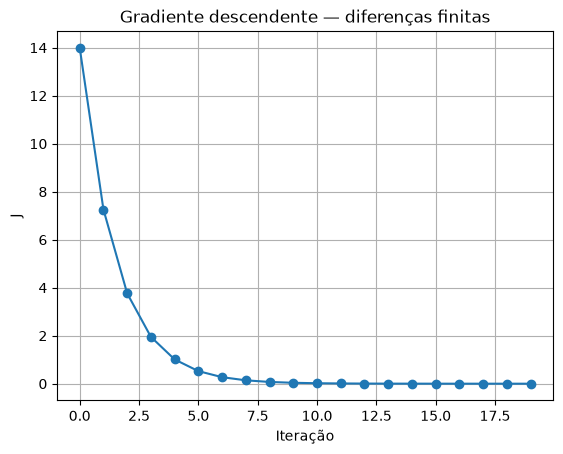

w_20 = tensor([1.9986])


In [42]:
import matplotlib.pyplot as plt

learning_rate = 0.01
iteracoes = 20

x = torch.arange(0, 4).float()
y = torch.arange(0, 8, 2).float()
w = torch.ones(1)
losses_finite = []

for i in range(iteracoes):
    J = J_func(w, x, y)
    grad = finite_difference_gradient(w, x, y)
    losses_finite.append(float(J))
    w = w - learning_rate * grad
    if i in (0, 1, 4, 9, 19):
        print(
            f'i={i:02d} J={float(J.detach()):.8f} '
            f'grad={float(grad):.8f} w={float(w.detach()):.8f}'
        )

plt.plot(losses_finite, marker='o')
plt.xlabel('Iteração')
plt.ylabel('J')
plt.title('Gradiente descendente — diferenças finitas')
plt.grid(True)
plt.show()

print('w_20 =', w)
assert losses_finite[-1] < losses_finite[0]
assert torch.allclose(w, torch.tensor([2.0]), atol=2e-3)


##Exercício 3.3

Repita o exercício 2 mas usando agora o calculando o gradiente usando o método backward() do pytorch. Confira se o primeiro valor do gradiente está de acordo com os valores anteriores. Execute essa próxima célula duas vezes. Os valores devem ser iguais.


i=00 J=14.00000000 grad=-28.00000000 w=1.27999997
i=01 J=7.25760031 grad=-20.16000175 w=1.48160005
i=04 J=1.01108503 grad=-7.52467680 w=1.80650830
i=09 J=0.03785419 grad=-1.45596528 w=1.96256089
i=19 J=0.00005306 grad=-0.05450988 w=1.99859834


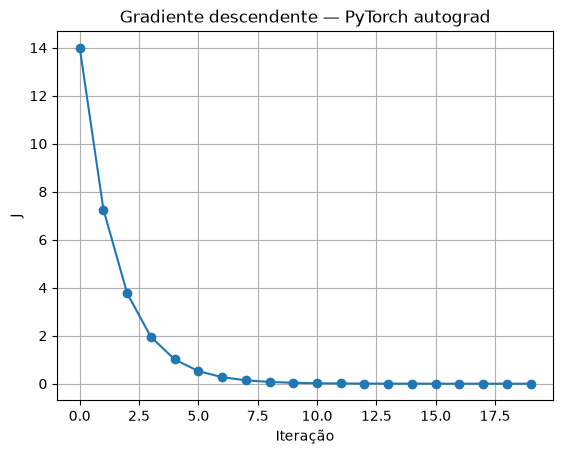

w_20 = tensor([1.9986])


In [43]:
learning_rate = 0.01
iteracoes = 20

x = torch.arange(0, 4).float()
y = torch.arange(0, 8, 2).float()
w = torch.ones(1, requires_grad=True)
losses_autograd = []

for i in range(iteracoes):
    J = J_func(w, x, y)
    losses_autograd.append(float(J.detach()))
    J.backward()
    grad = w.grad.detach().clone()
    with torch.no_grad():
        w -= learning_rate * w.grad
    w.grad.zero_()
    if i in (0, 1, 4, 9, 19):
        print(
            f'i={i:02d} J={float(J.detach()):.8f} '
            f'grad={float(grad):.8f} w={float(w.detach()):.8f}'
        )

plt.plot(losses_autograd, marker='o')
plt.xlabel('Iteração')
plt.ylabel('J')
plt.title('Gradiente descendente — PyTorch autograd')
plt.grid(True)
plt.show()

print('w_20 =', w.detach())
assert losses_autograd[-1] < losses_autograd[0]
assert torch.allclose(w.detach(), torch.tensor([2.0]), atol=2e-3)
assert np.allclose(losses_autograd, losses_finite, atol=2e-3)


##Exercício 3.4

Quais são as restrições na escolha dos valores de $\Delta w$ no cálculo do gradiente por diferenças finitas?

**Resposta:** $\Delta w$ deve ser pequeno para que a diferença central aproxime a derivada local e reduza o erro de truncamento, mas não pode ser tão pequeno a ponto de $J(w+\Delta w)$ e $J(w-\Delta w)$ se tornarem numericamente indistinguíveis. Nesse caso, cancelamento catastrófico e arredondamento de ponto flutuante dominam o resultado. O valor também precisa ser representável na precisão usada e deve ser escolhido em relação à escala de $w$. Assim, existe um compromisso entre erro de truncamento (passo grande) e erro numérico (passo pequeno).


##Exercício 3.5

Até agora trabalhamos com $w$ contendo apenas um parâmetro. Suponha agora que $w$ seja uma matriz com $N$ parâmetros e que o custo para executar $(x_i w - y_i)^2$ seja $O(N)$.
> a) Qual é o custo computacional para fazer uma única atualização (um passo de gradiente) dos parâmetros de $w$ usando o método das diferencas finitas?
>
> b) Qual é o custo computacional para fazer uma única atualização (um passo de gradiente) dos parâmetros de $w$ usando o método do backpropagation?



**Resposta (com justificativa):**

**a)** Diferenças finitas têm custo $O(N^2)$ por atualização. Para calcular as $N$ derivadas parciais por diferença central são necessárias aproximadamente $2N$ avaliações de $J$; cada avaliação custa $O(N)$. Além disso, a atualização dos parâmetros custa $O(N)$, que não altera a ordem dominante.

**b)** Backpropagation tem custo $O(N)$ por atualização. Uma passagem forward custa $O(N)$ e a passagem backward calcula todos os $N$ gradientes em uma única travessia do grafo, com custo da mesma ordem do forward. A atualização também custa $O(N)$.


##Exercício 3.6

Qual o custo (entropia cruzada) esperado para um exemplo (uma amostra) no começo do treinamento de um classificador inicializado aleatoriamente?

A equação da entropia cruzada para cada exemplo é:
$$L = - \sum_{j=0}^{K-1} y_j \log p_j, $$
Onde:

- K é o número de classes;

- $y_j=1$ se $j$ é a classe do exemplo (ground-truth), 0 caso contrário. Ou seja, $y$ é um vetor one-hot;

- $p_j$ é a probabilidade predita pelo modelo para a classe $j$.

A resposta tem que ser em função de uma ou mais das seguintes variáveis:

- K = número de classes

- B = batch size

- D = dimensão de qualquer vetor do modelo

- LR = learning rate

**Resposta:** no início do treinamento, supondo logits aleatórios simétricos, as probabilidades esperadas são aproximadamente uniformes: $p_j \approx 1/K$. Como apenas a classe correta possui $y_j=1$, a entropia cruzada esperada **por exemplo** é

$$L \approx -\log(1/K)=\log K.$$

Ela não depende de $B$, $D$ ou da taxa de aprendizado. Se a perda for **somada** em um batch, o valor esperado será $B\log K$; se for calculada pela média, continuará sendo $\log K$.


# Parte 4

## 4.1 Identificação do uso de IA.

A geração de texto, imagens e vídeos por modelos generativos tem proporcionado grandes feitos. Porém, a IA ainda não se distingue totalmente da criação por seres humanos. Ela ainda é facilmente identificada por padrões, estilos e alucinações.

Escreva todos os usos que você identificou o uso de IA nos slides da aula 1.
Liste qual o slide, qual foi o uso e como você identificou.

**Resposta:** os slides da Aula 1 não foram disponibilizados junto ao notebook-modelo nem no enunciado recebido. Portanto, não é possível listar, com evidência, números de slides ou usos de IA específicos sem inventar informações. Esta resposta deve ser complementada após inspeção visual dos slides originais, registrando para cada ocorrência: número do slide, elemento possivelmente gerado por IA e indícios observáveis (por exemplo, artefatos visuais, texto incoerente ou atribuição explícita da ferramenta).


# Parte 5

**Questionário Final — respostas pessoais a confirmar pelo aluno:**

- É sua primeira vez programando em Python? **Não informado.**
- É sua primeira vez programando em PyTorch? **Não informado.**
- É sua primeira vez programando com Redes Neurais? **Não informado.**

Essas respostas dependem da experiência pessoal do aluno e não foram inferidas por IA.


# Comentários

---
**Comentários:**

Ferramenta: OpenAI Codex (modelo GPT-5)

Utilização: Utilizado como apoio para interpretar o notebook-modelo, desenvolver e revisar as soluções de Python, NumPy e PyTorch, criar testes de correção, documentar as justificativas e executar o notebook. Não foi utilizado para inventar respostas pessoais nem observações sobre slides não fornecidos.

Ferramenta: Python — biblioteca padrão

Utilização: Utilizada nas soluções de contagem, expressões regulares, geração pseudoaleatória, leitura de arquivos e reservoir sampling.

Ferramenta: NumPy

Utilização: Utilizado nas operações vetorizadas, normalizações, softmax estável e codificação one-hot.

Ferramenta: PyTorch

Utilização: Utilizado para construir o grafo computacional, calcular gradientes por autograd e comparar com diferenças finitas.

Ferramenta: Matplotlib

Utilização: Utilizado para visualizar a redução da função de perda nos exercícios de gradiente descendente.

Ferramenta: Jupyter Notebook / nbclient

Utilização: Utilizado para executar todas as células e registrar as evidências no arquivo entregue.

Referências:

- Notebook-modelo da disciplina: https://colab.research.google.com/drive/14cQOb6nJwOcLq7Jwb_47gxB74p_E5_3E
- Python `collections.Counter`: https://docs.python.org/3/library/collections.html#collections.Counter
- Python `random`: https://docs.python.org/3/library/random.html
- NumPy: https://numpy.org/doc/stable/
- PyTorch Autograd: https://pytorch.org/docs/stable/notes/autograd.html
- Matplotlib: https://matplotlib.org/stable/
---


# Fim do notebook

In [44]:
print("Notebook concluído e validado.")


Notebook concluído e validado.
